In [8]:
from pathlib import Path

sample_dir = Path("/data/bvcoe2026/CMS-OD/samples")

print("Directory exists:", sample_dir.exists())

if sample_dir.exists():
    root_files = sorted(sample_dir.glob("*.root"))
    print("Number of ROOT files:", len(root_files))

    for file in root_files:
        print(file.name)
else:
    print("Sample directory not found.")

Directory exists: True
Number of ROOT files: 8
DY-test.root
DY-train.root
Higgs-test.root
Higgs-train.root
Top-test.root
Top-train.root
WW-test.root
WW-train.root


In [2]:
import uproot

file_path = str(root_files[0])

with uproot.open(file_path) as f:
    print("Objects inside file:")
    print(f.keys())

Objects inside file:
['Events;1']


In [3]:
with uproot.open(file_path) as f:
    tree = f["Events"]

    print("Total events:", tree.num_entries)
    print("Available branches:")
    print(tree.keys())

Total events: 16064629
Available branches:
['Electron_charge', 'Electron_eta', 'Electron_mass', 'Electron_mvaFall17V2Iso_WP90', 'Electron_phi', 'Electron_pt', 'Jet_btagDeepFlavB', 'Jet_eta', 'Jet_jetId', 'Jet_mass', 'Jet_phi', 'Jet_pt', 'Jet_puId', 'Muon_charge', 'Muon_eta', 'Muon_mass', 'Muon_pfRelIso04_all', 'Muon_phi', 'Muon_pt', 'Muon_tightId', 'PuppiMET_phi', 'PuppiMET_pt', 'dphill', 'mjj', 'mll', 'mth', 'mtw2', 'nJet', 'ptll']


In [4]:
with uproot.open(file_path) as f:
    tree = f["Events"]

    for name in tree.keys():
        if any(x in name for x in ["Muon_pt", "Electron_pt", "Jet_pt", "MET_pt"]):
            print(name)

Electron_pt
Jet_pt
Muon_pt
PuppiMET_pt


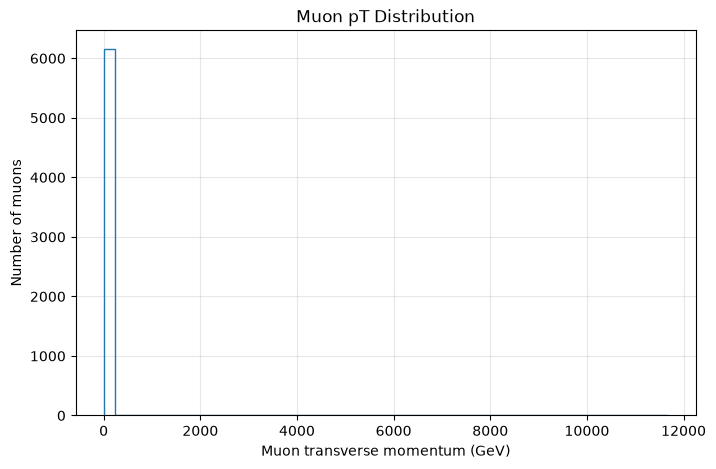

In [5]:
import awkward as ak
import matplotlib.pyplot as plt

with uproot.open(file_path) as f:
    tree = f["Events"]
    muon_pt = tree["Muon_pt"].array(
        entry_stop=10000,
        library="ak"
    )

values = ak.to_numpy(ak.flatten(muon_pt))

plt.figure(figsize=(8, 5))
plt.hist(values, bins=50, histtype="step")
plt.xlabel("Muon transverse momentum (GeV)")
plt.ylabel("Number of muons")
plt.title("Muon pT Distribution")
plt.grid(alpha=0.3)
plt.show()

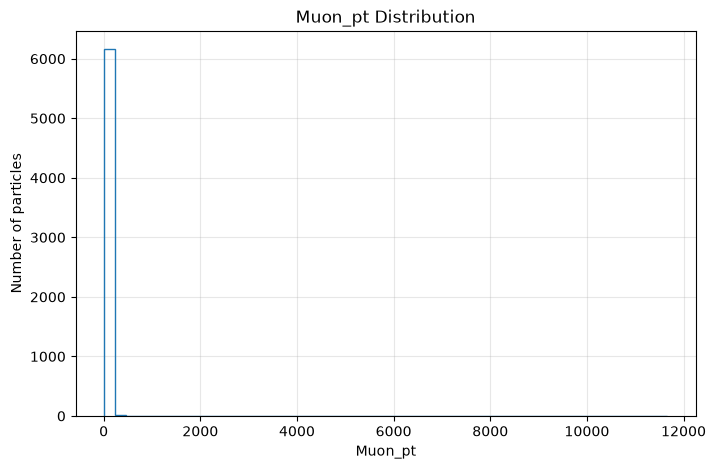

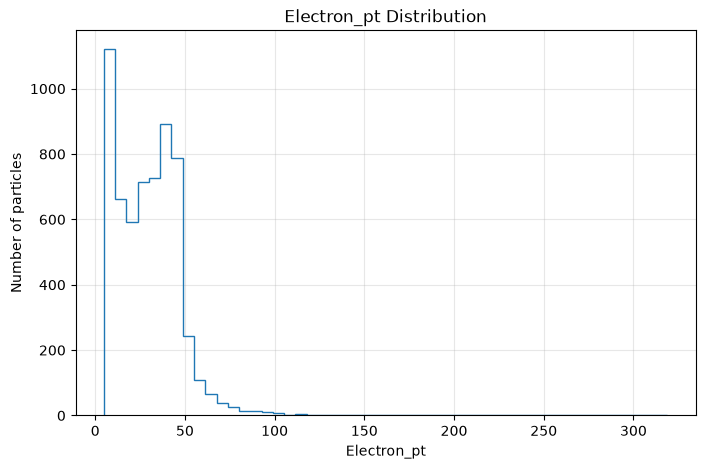

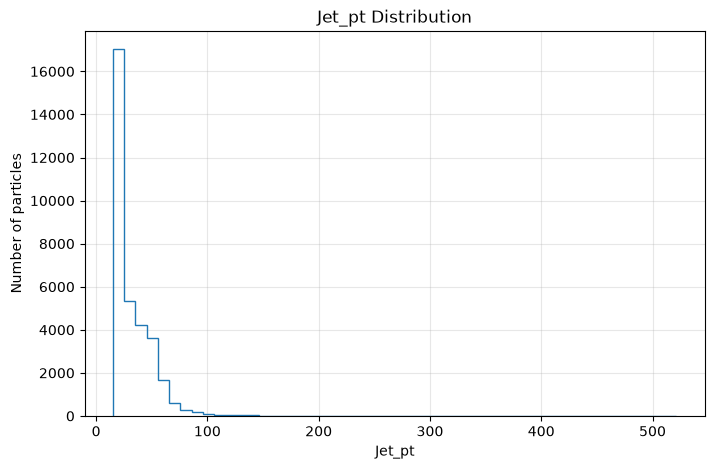

In [6]:
variables = ["Muon_pt", "Electron_pt", "Jet_pt"]

with uproot.open(file_path) as f:
    tree = f["Events"]

    for variable in variables:
        if variable not in tree.keys():
            print("Skipping missing branch:", variable)
            continue

        arr = tree[variable].array(
            entry_stop=10000,
            library="ak"
        )
        values = ak.to_numpy(ak.flatten(arr))

        plt.figure(figsize=(8, 5))
        plt.hist(values, bins=50, histtype="step")
        plt.xlabel(variable)
        plt.ylabel("Number of particles")
        plt.title(f"{variable} Distribution")
        plt.grid(alpha=0.3)
        plt.show()

Found DY: /data/bvcoe2026/CMS-OD/samples/DY-train.root
Found Higgs: /data/bvcoe2026/CMS-OD/samples/Higgs-train.root
Found Top: /data/bvcoe2026/CMS-OD/samples/Top-train.root
Found WW: /data/bvcoe2026/CMS-OD/samples/WW-train.root


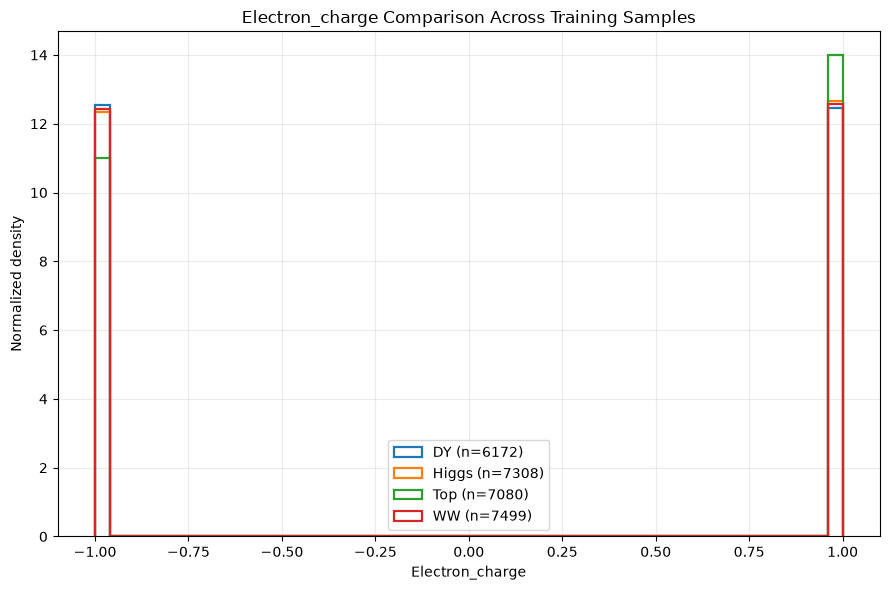

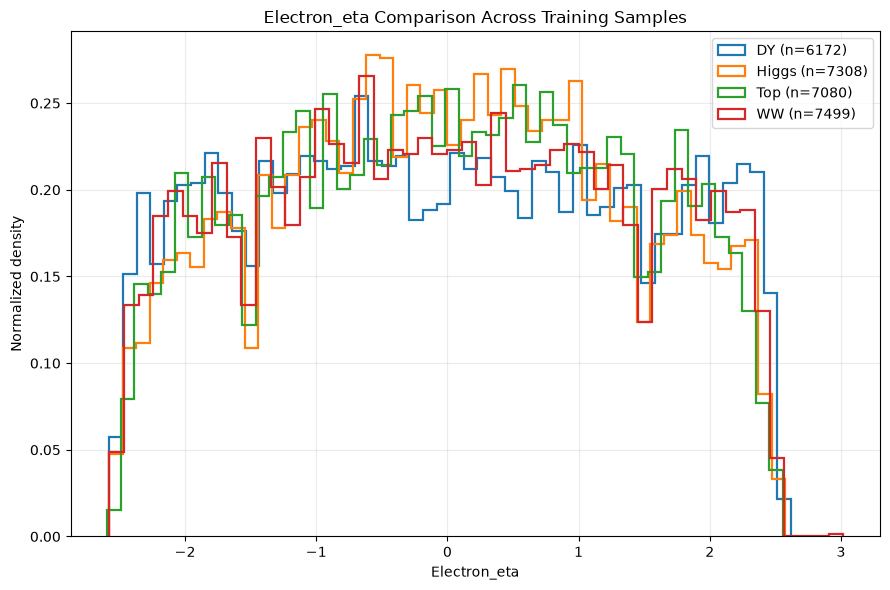

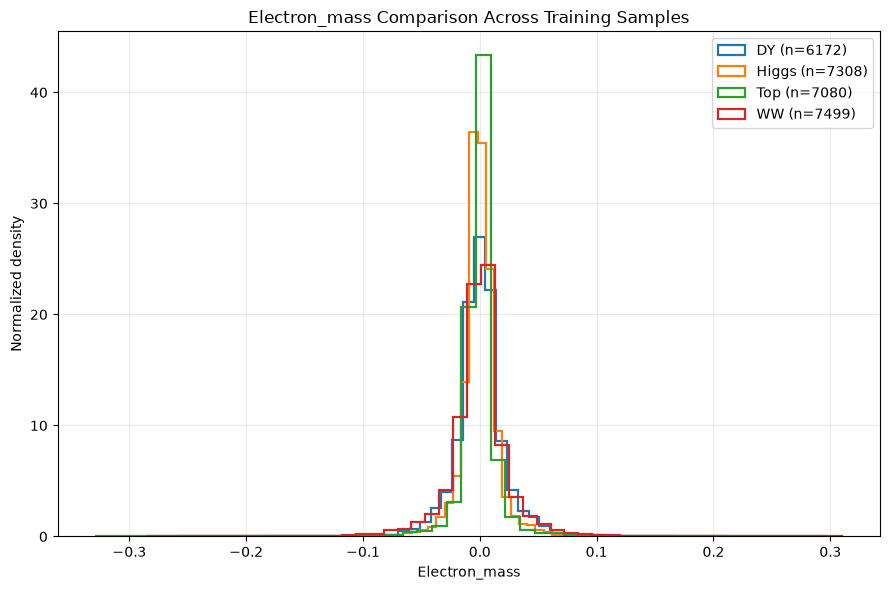

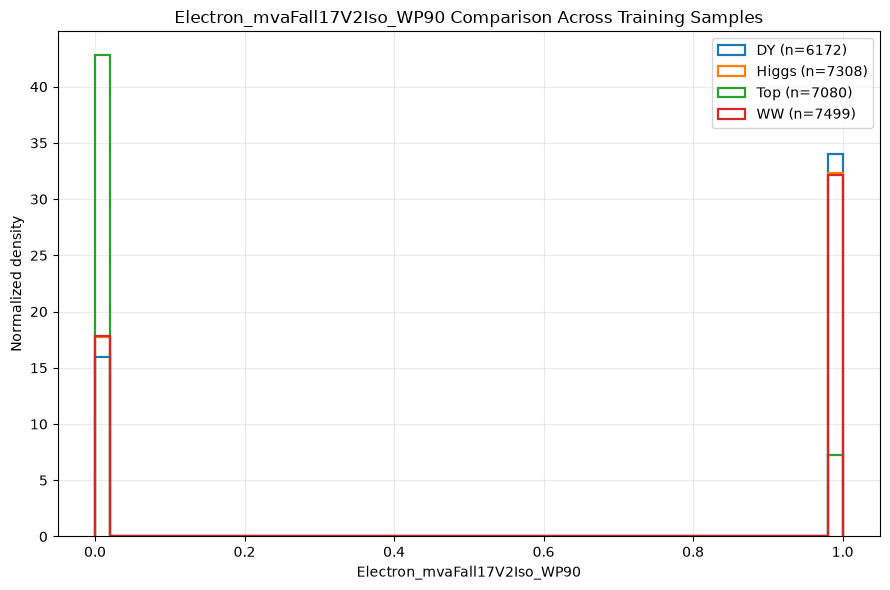

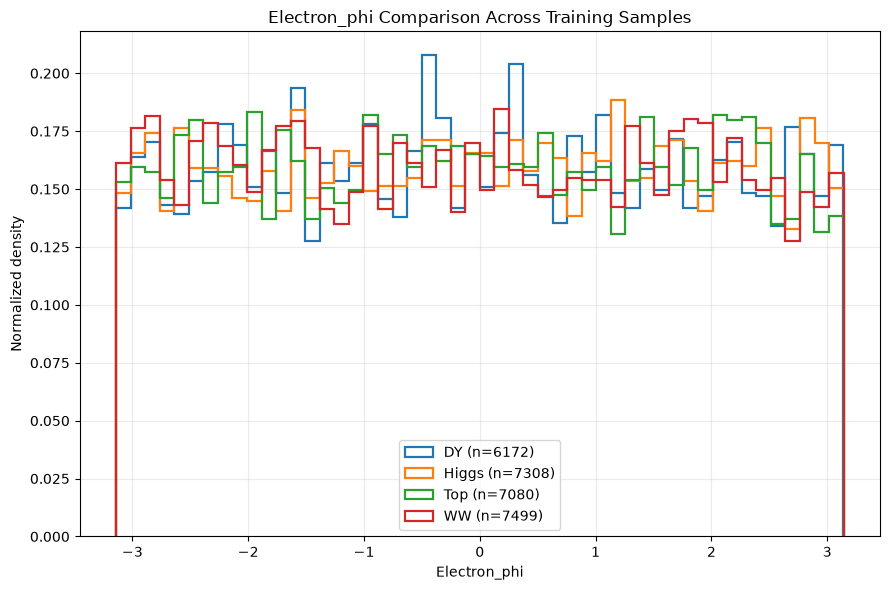

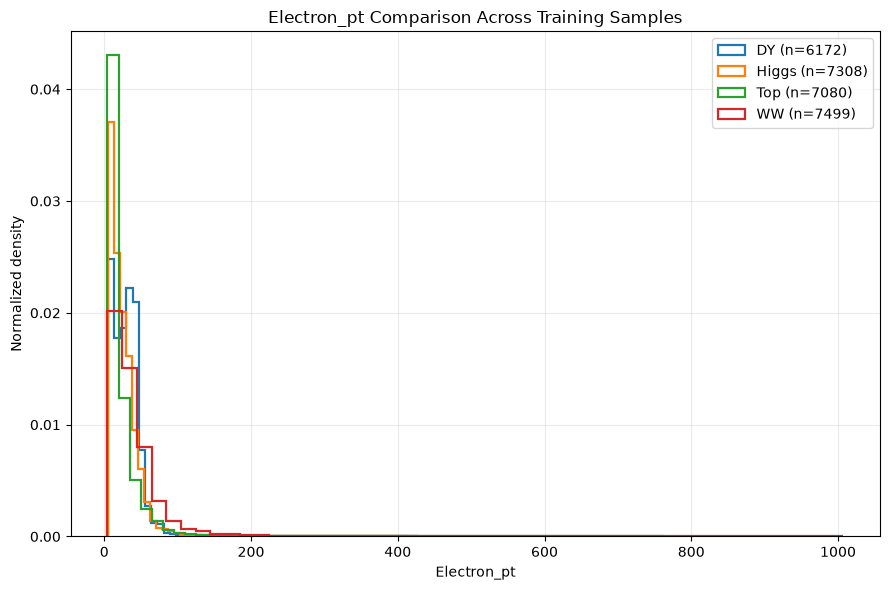

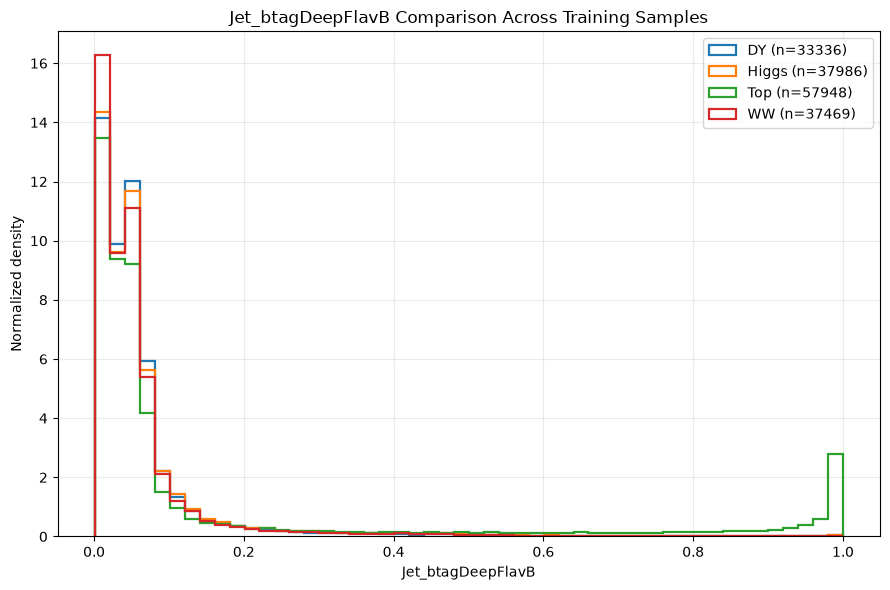

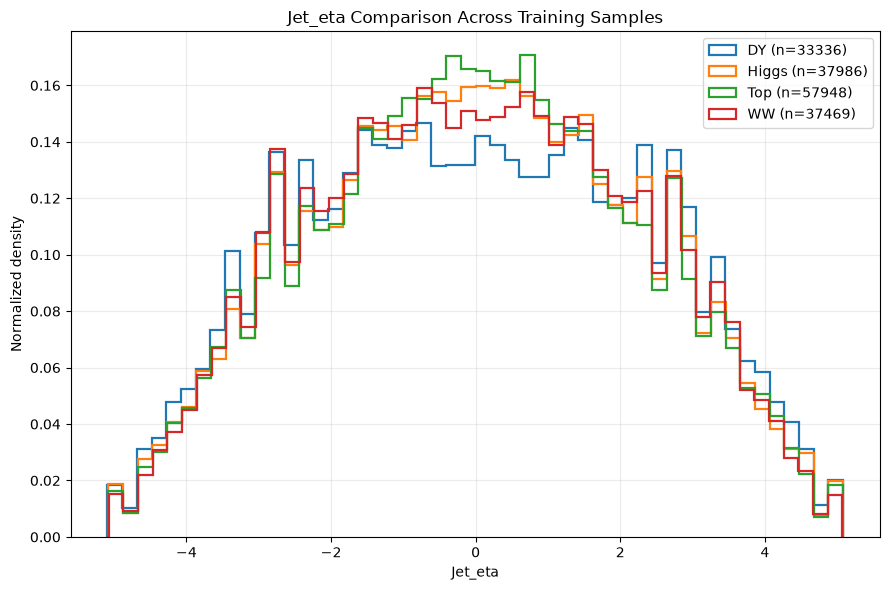

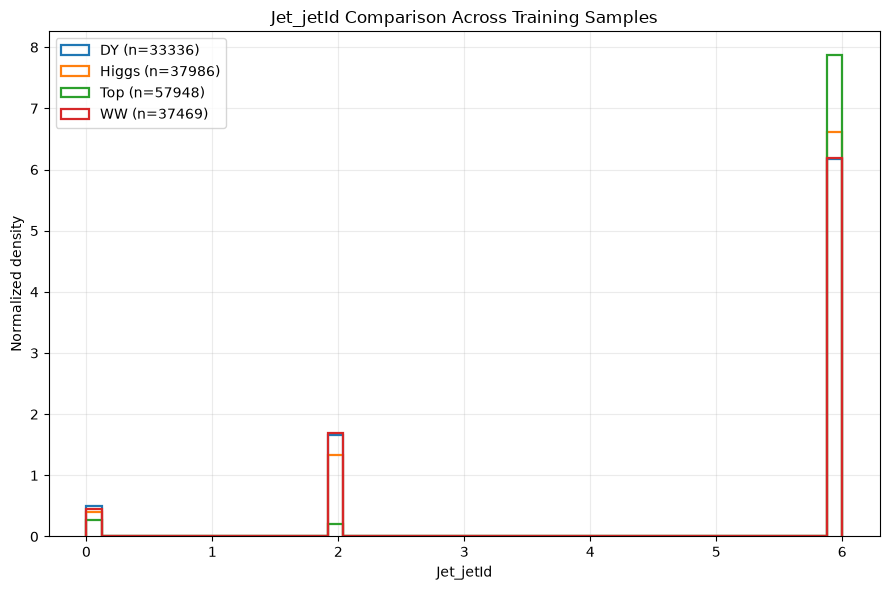

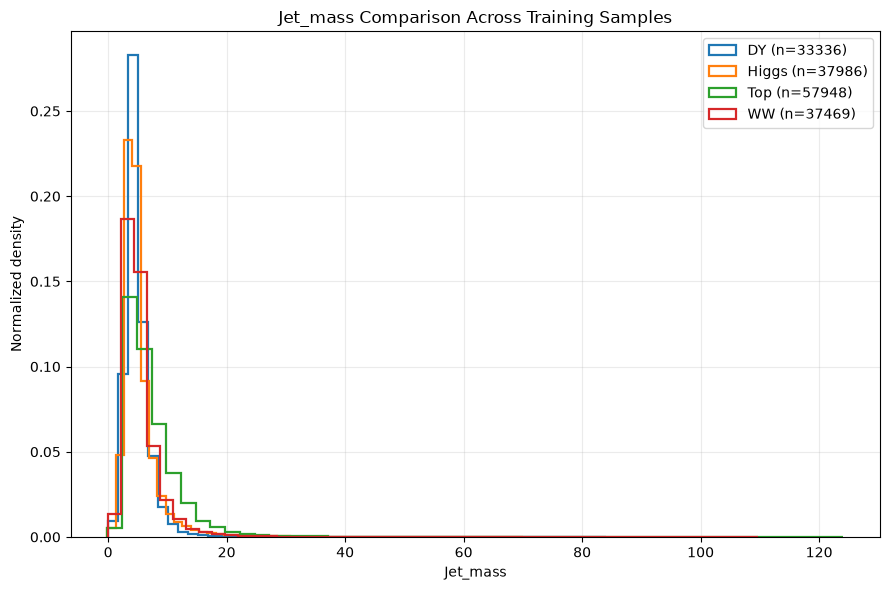

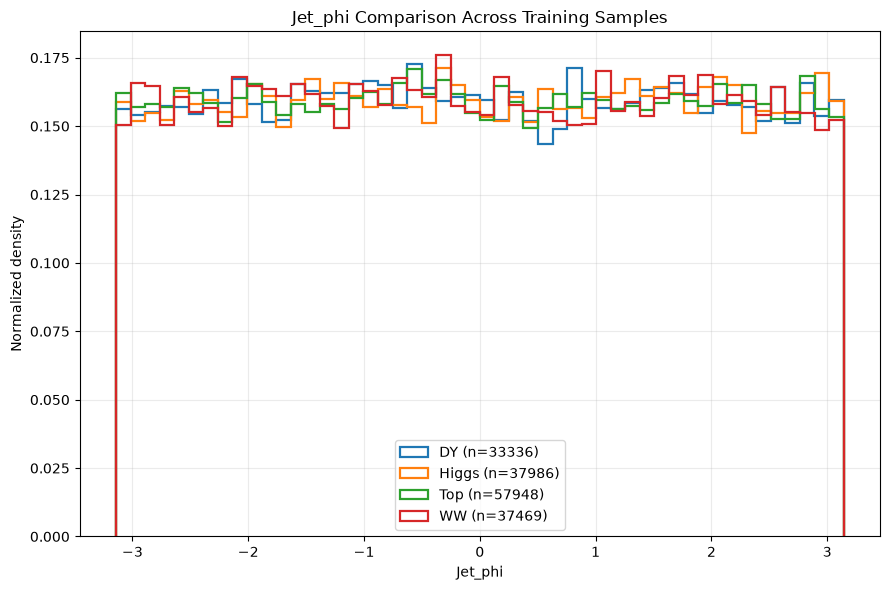

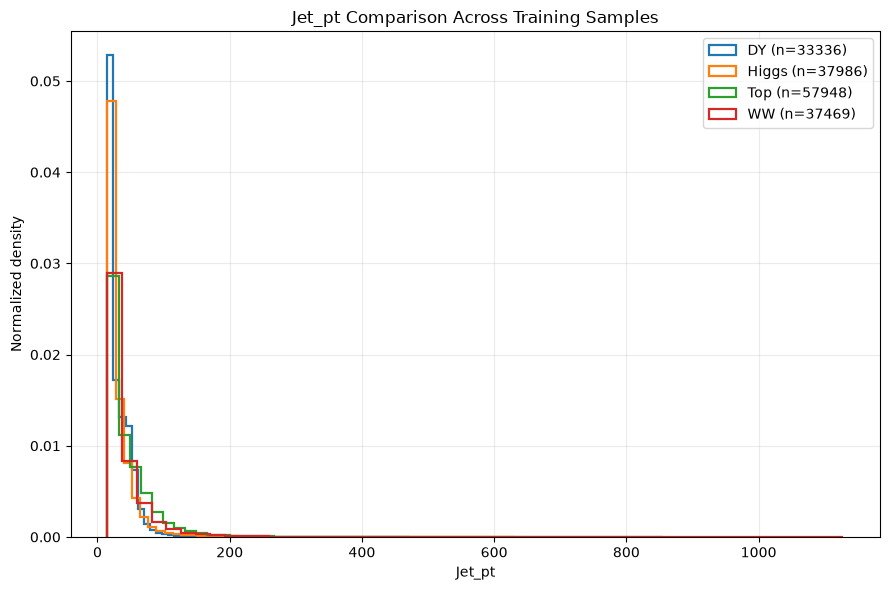

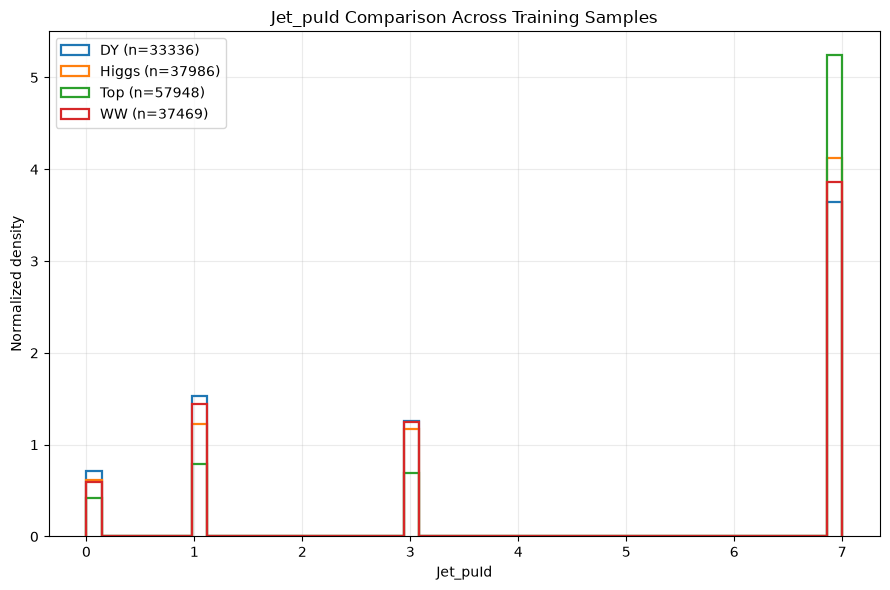

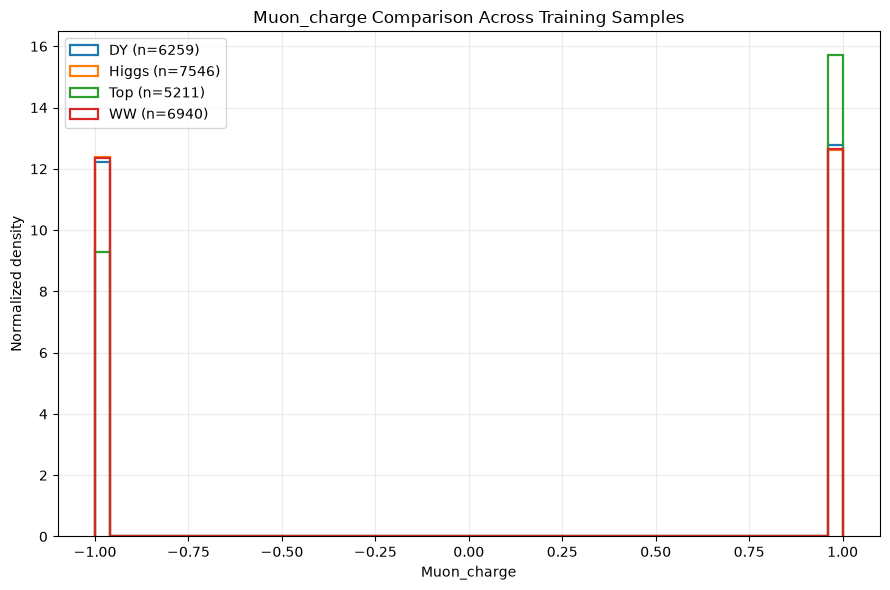

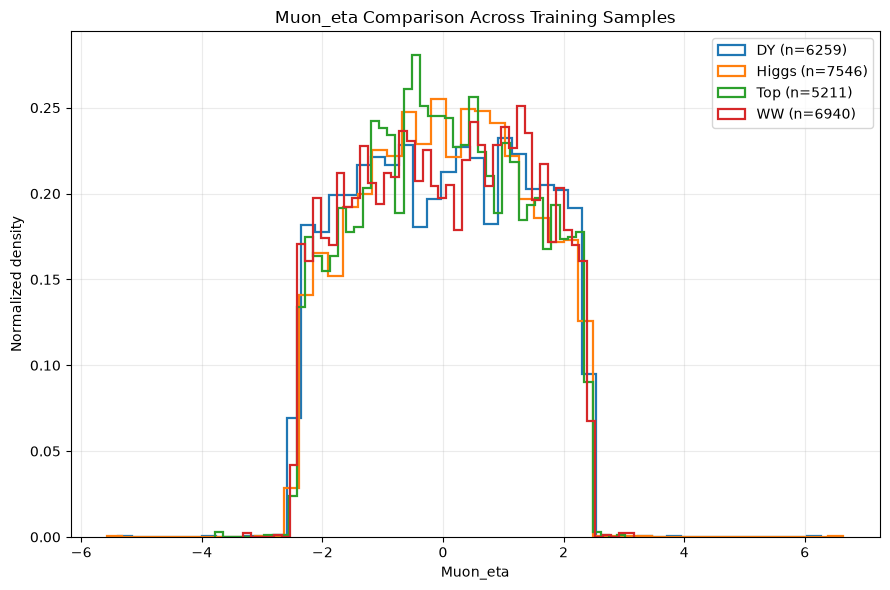

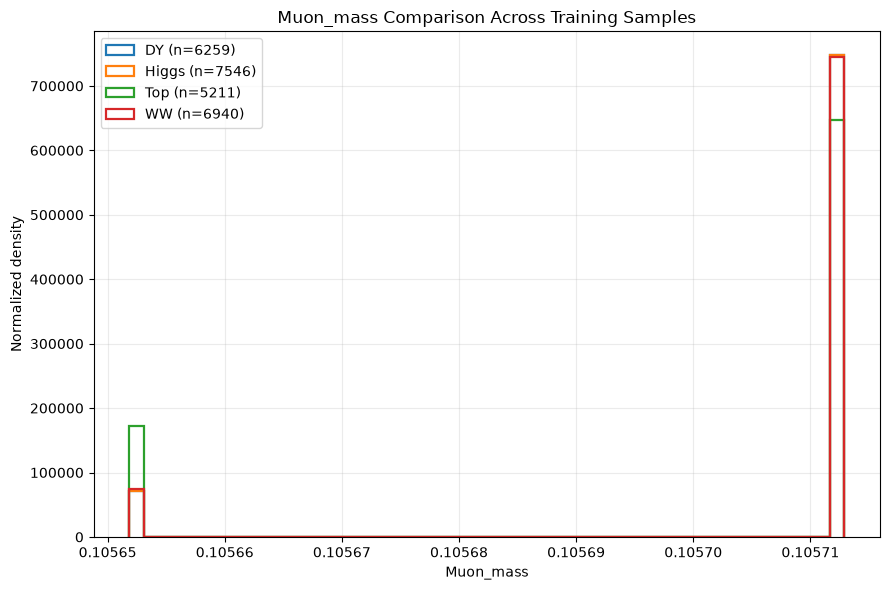

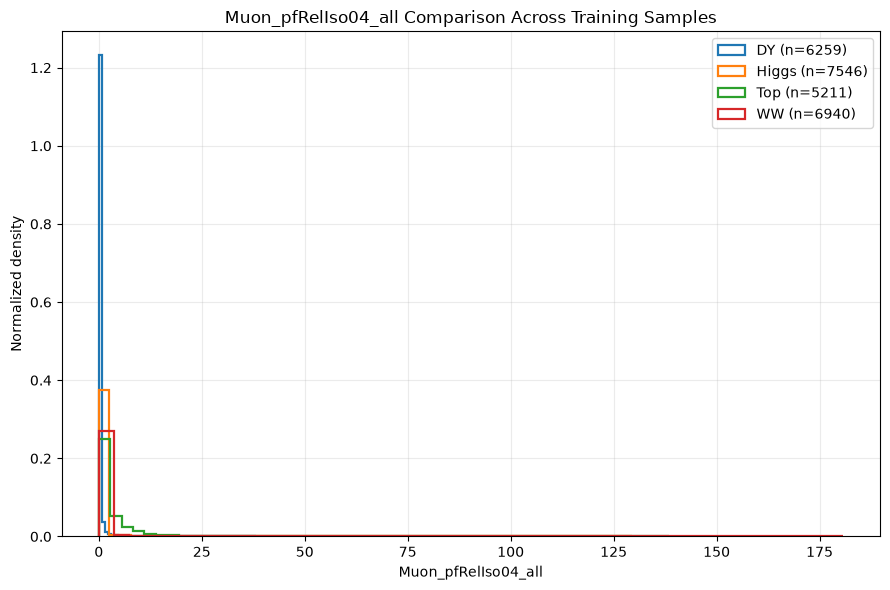

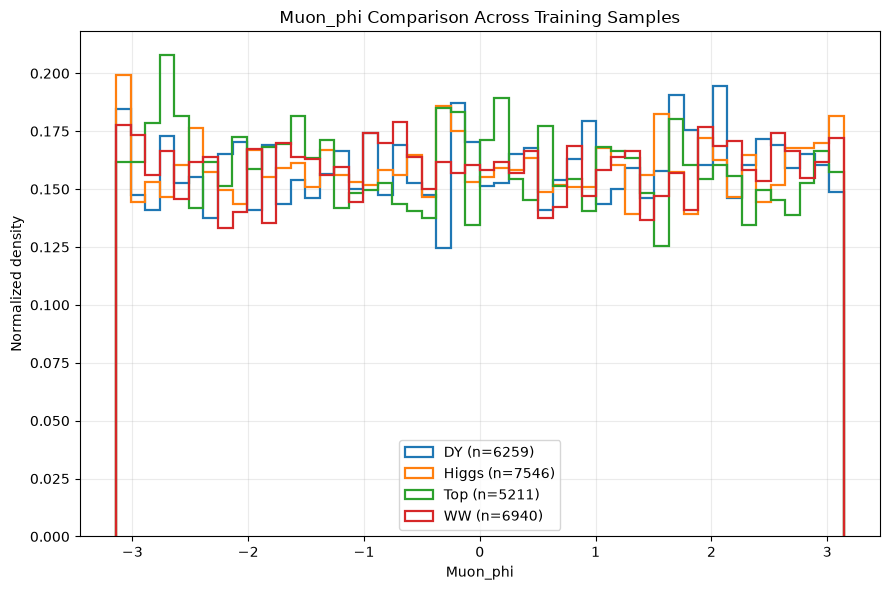

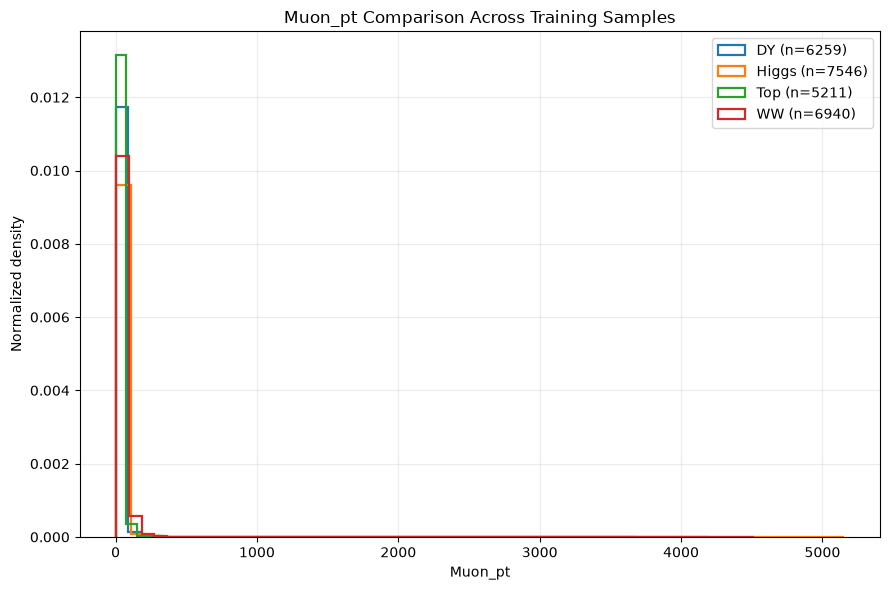

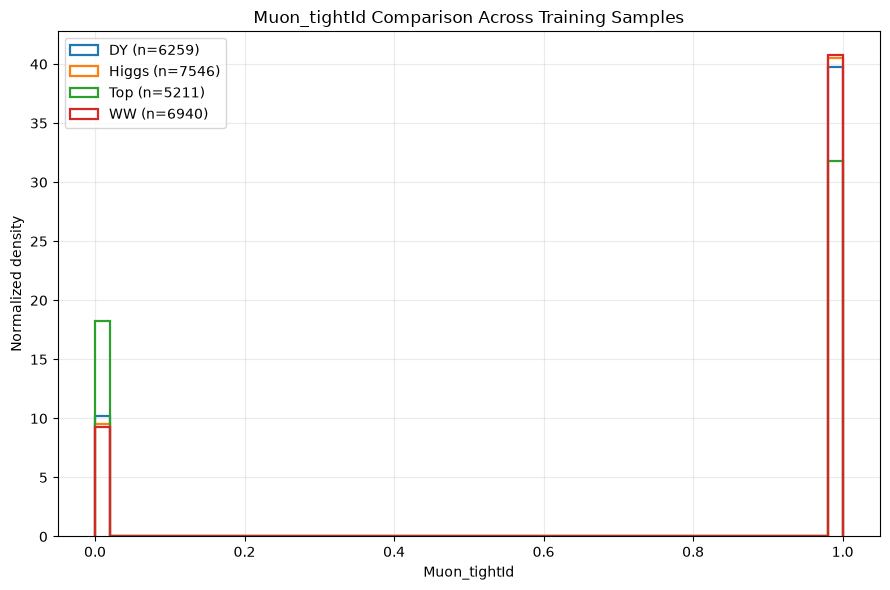

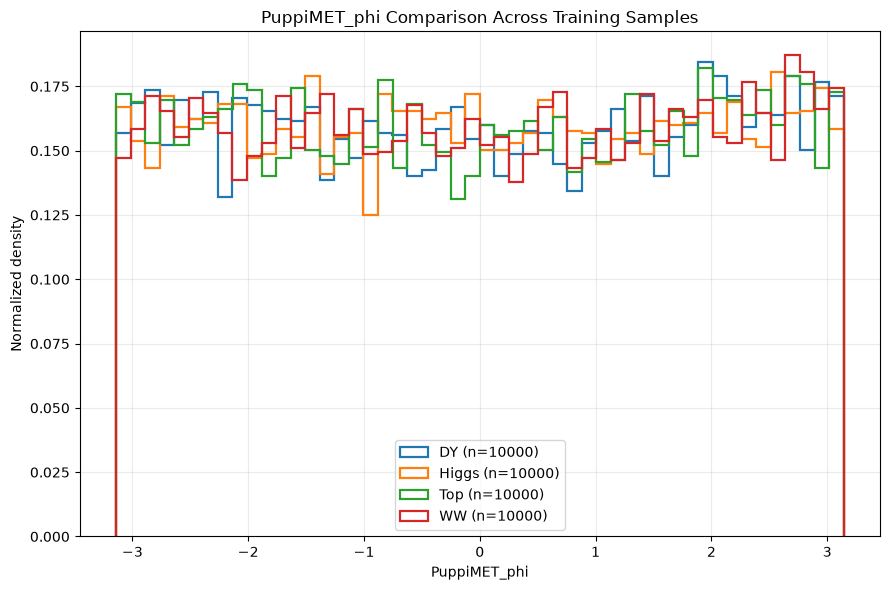

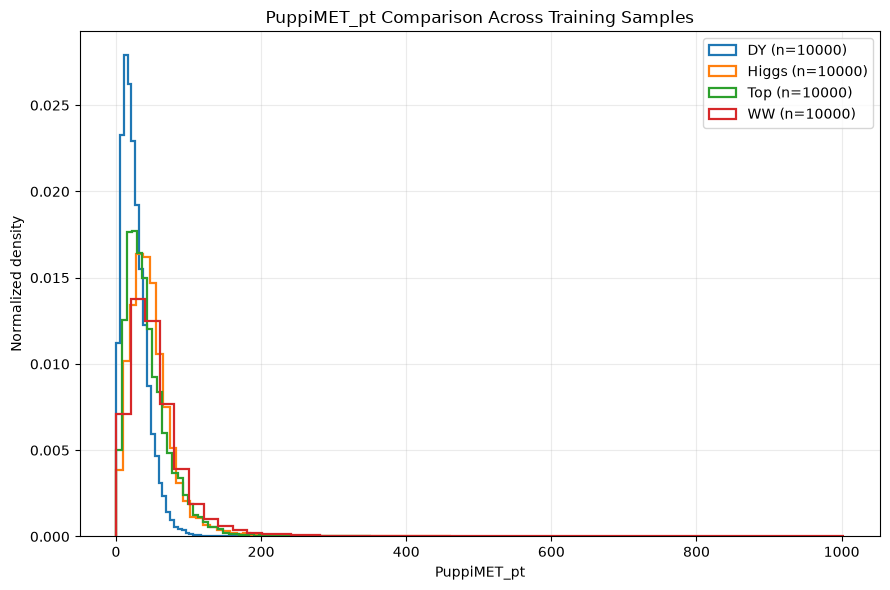

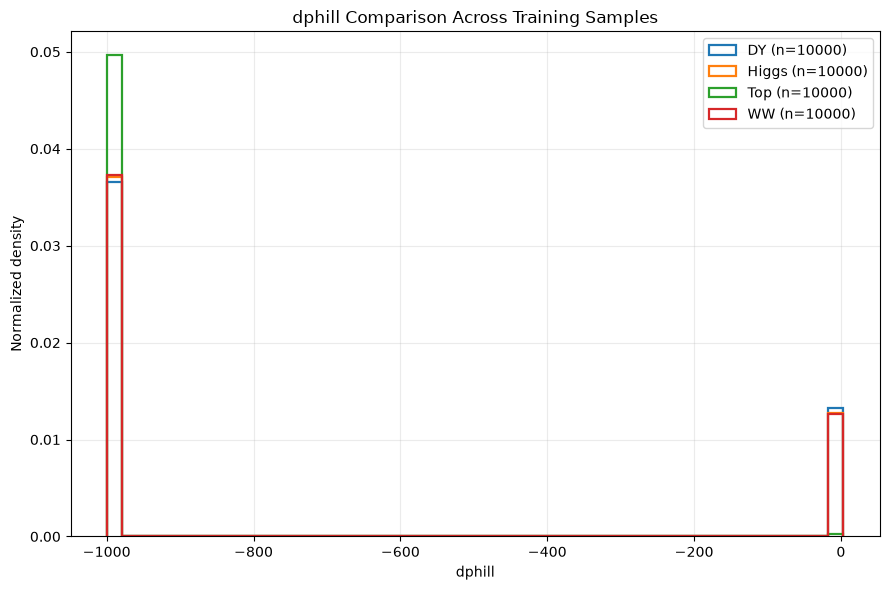

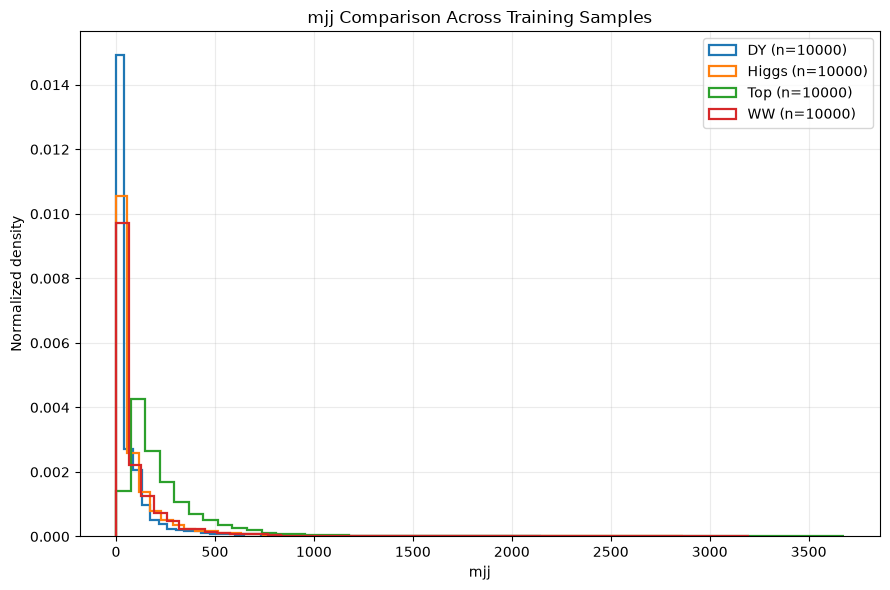

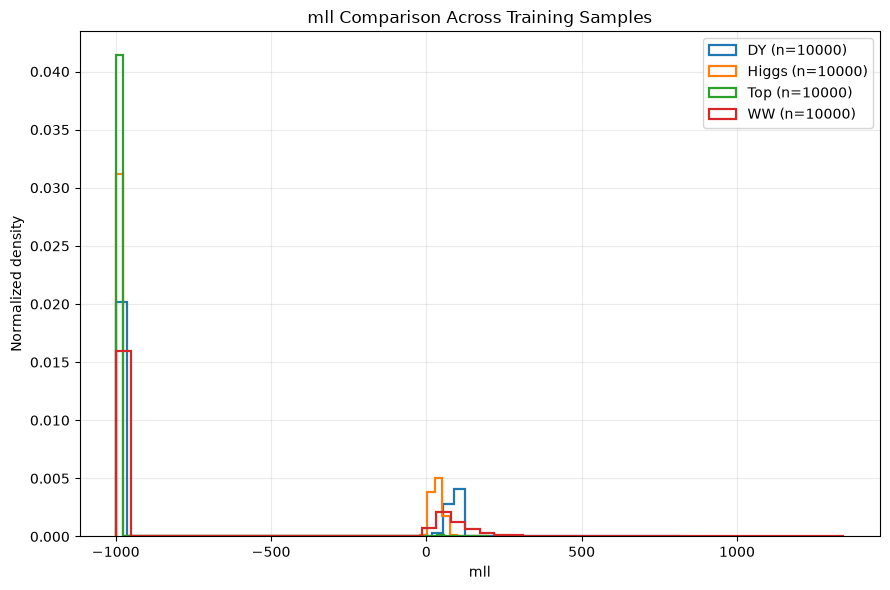

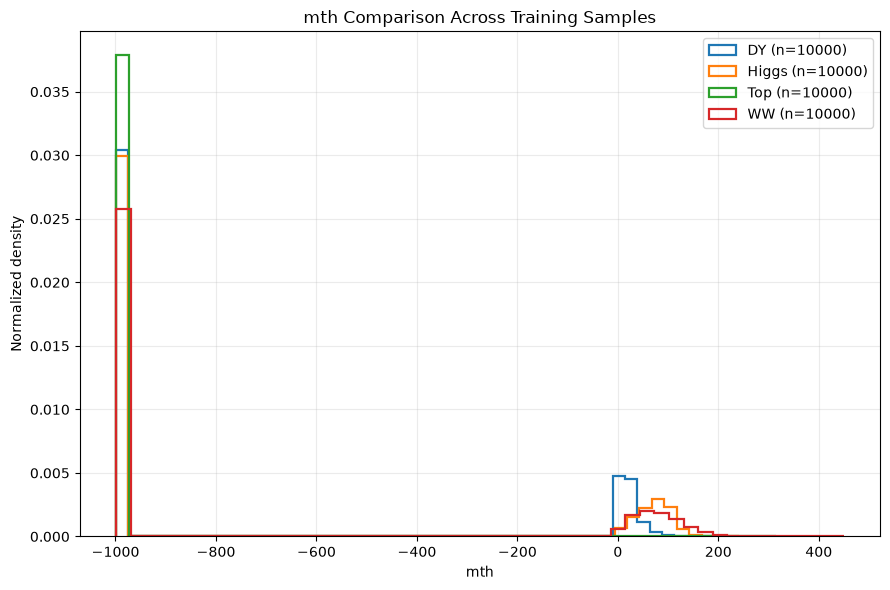

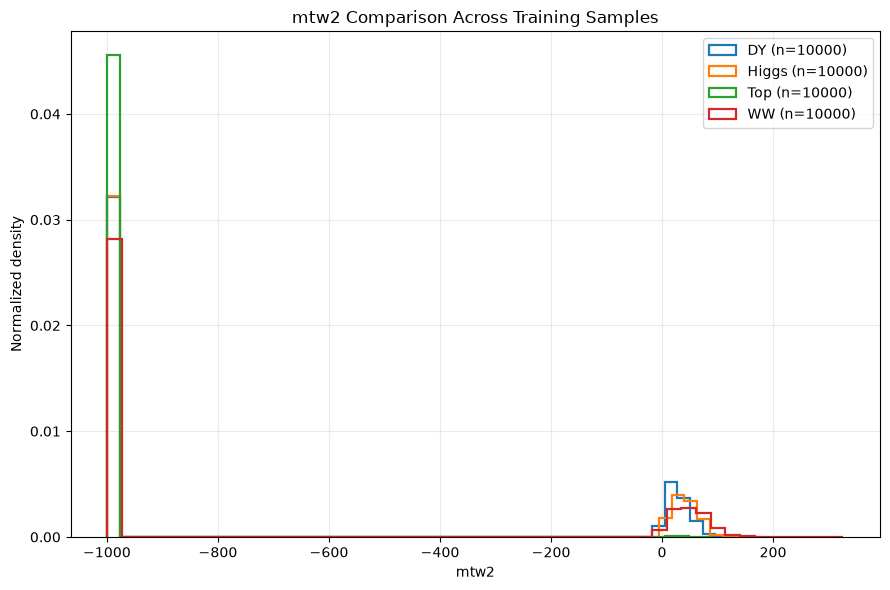

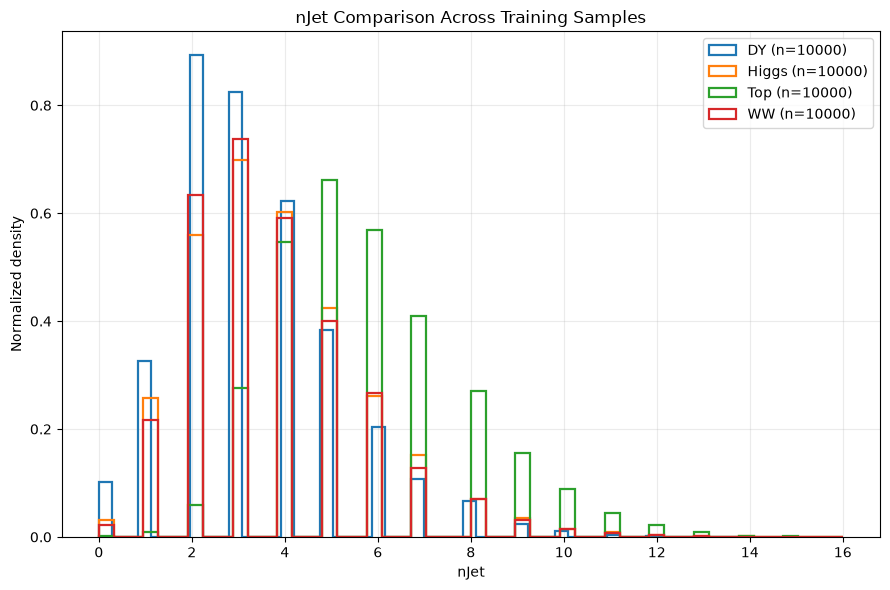

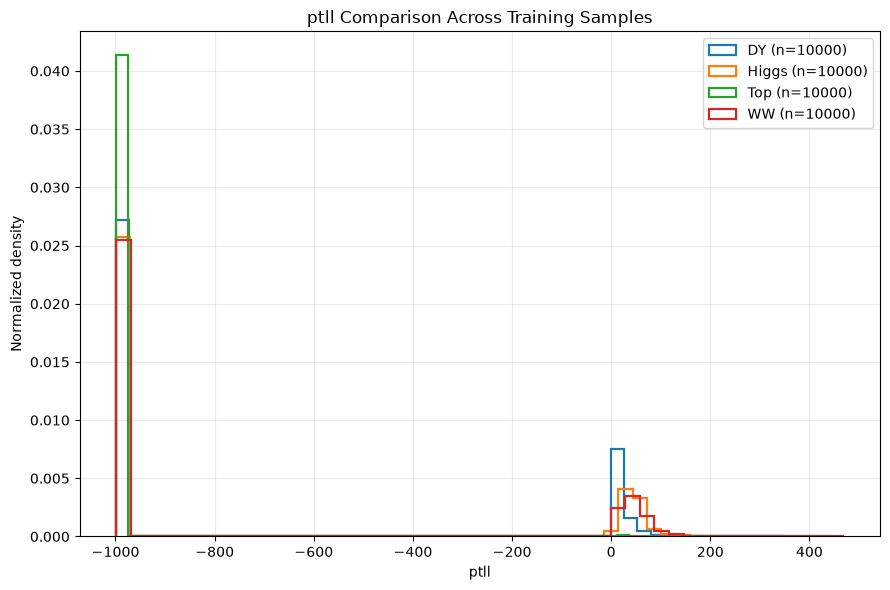


Plots saved in: /home/jovyan/hsf-india-bvcoe-2026/superimposed_plots


In [10]:

from pathlib import Path
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt

# Directory containing workshop samples
sample_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# Map labels to the actual training ROOT files
sample_files = {
    "DY": sample_dir / "DY-train.root",
    "Higgs": sample_dir / "Higgs-train.root",
    "Top": sample_dir / "Top-train.root",
    "WW": sample_dir / "WW-train.root",
}

# Variables to plot
mvaVariables = [
    "Electron_charge",
    "Electron_eta",
    "Electron_mass",
    "Electron_mvaFall17V2Iso_WP90",
    "Electron_phi",
    "Electron_pt",
    "Jet_btagDeepFlavB",
    "Jet_eta",
    "Jet_jetId",
    "Jet_mass",
    "Jet_phi",
    "Jet_pt",
    "Jet_puId",
    "Muon_charge",
    "Muon_eta",
    "Muon_mass",
    "Muon_pfRelIso04_all",
    "Muon_phi",
    "Muon_pt",
    "Muon_tightId",
    "PuppiMET_phi",
    "PuppiMET_pt",
    "dphill",
    "mjj",
    "mll",
    "mth",
    "mtw2",
    "nJet",
    "ptll",
]

# Output directory for graphs
output_dir = Path("superimposed_plots")
output_dir.mkdir(parents=True, exist_ok=True)

# Check file availability
available_samples = {}

for label, path in sample_files.items():
    if path.exists():
        available_samples[label] = path
        print(f"Found {label}: {path}")
    else:
        print(f"MISSING {label}: {path}")

if len(available_samples) < 2:
    raise FileNotFoundError(
        "Need at least two sample files. Check sample_dir "
        "and the filenames printed above."
    )

# Cache the event trees so each file is opened only once
trees = {}

for label, path in available_samples.items():
    root_file = uproot.open(path)

    if "Events" not in root_file:
        print(f"Skipping {label}: no Events tree")
        root_file.close()
        continue

    trees[label] = (root_file, root_file["Events"])

# Generate one superimposed graph per variable
for variable in mvaVariables:
    fig, ax = plt.subplots(figsize=(9, 6))
    plotted = 0

    for label, (root_file, tree) in trees.items():
        if variable not in tree.keys():
            print(f"{label}: {variable} not found; skipping")
            continue

        try:
            arr = tree[variable].array(
                entry_stop=10000,
                library="ak"
            )

            # Flatten particle collections into individual values
            values = ak.to_numpy(ak.flatten(arr, axis=None))
            values = values.astype(float)
            values = values[np.isfinite(values)]

            if len(values) == 0:
                continue

            ax.hist(
                values,
                bins=50,
                histtype="step",
                density=True,
                linewidth=1.6,
                label=f"{label} (n={len(values)})"
            )

            plotted += 1

        except Exception as exc:
            print(f"Could not plot {variable} from {label}: {exc}")

    if plotted >= 2:
        ax.set_xlabel(variable)
        ax.set_ylabel("Normalized density")
        ax.set_title(f"{variable} Comparison Across Training Samples")
        ax.legend()
        ax.grid(alpha=0.25)
        fig.tight_layout()

        safe_name = variable.replace("/", "_")
        fig.savefig(output_dir / f"{safe_name}.png", dpi=150)
        plt.show()
    else:
        print(f"Not enough samples contain {variable}; no plot saved.")
        plt.close(fig)

# Close ROOT files
for root_file, tree in trees.values():
    root_file.close()

print(f"\nPlots saved in: {output_dir.resolve()}")
